As mentioned in the README of l4_notes, the third issue led to an innovation of layer type in neural network, and that innovation is batch normalization. 

## Preparation

In [1]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

# read file
words = open('../names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


Since the process of training is altered, the ```split_loss``` function is changed as well. So we will not include it here. 

# Implementation of Batch Normalization

The idea of the third issue is that we want to keep the Gaussian Distribution across different layers upon initialization. The original approach achieves by adding additional scaling factors to the weights (not bias) of the linear layers. 

However, there is a much more direct way to do this: we manually adjust ```hpreact``` before it goes through tanh function with this line:
```hpreact = (hpreact - hpreact.mean(0, keepdims=True)) / hpreact.std(0, keepdims=True)```

Sadly, we cannot insert only this line into the training loop since in that we are forcing the distribution of hpreact to be perfectly Gaussian in every iteration, which eliminates the freedom for the values to move around to find its most comfortable place. (The result is train train 2.7528116703033447 val 2.7768993377685547)

And the solution is very direct as well: after we force it to be Gaussian, we allow it to be scaled (by some weight) and moved (by a bias) again. That means that we need another two parameters, we can name them ```bngain``` (batch normalization gain) and ```bnbis``` (batch normalization bias). 

This change, again leads to more issue: 
* if we are forcing the distribution of hpreact to be Gaussian, then the bias we add before, b2 is useless, so we can just remove that parameters, or that waste computer's resource. 
* Now the prediction of the next character depends on a batch mean and batch standard deviation, which does not exist during the deployment of the model. Therefore, we need a fixed value in the end of the training for deploment, or two variables initialized before training and changed during the training (running mean and running std). And we will show the implementation of both of these ways. And as you will see, the results of both approaches will end up in a similar place, so either of them is feasible and reliable. (for me, since the running approach fits each randomized batch more closely, i prefer the the running one.)
* Since the process of training loop is changing, the function content of ```split_loss``` and deployment needs to change as well to match the training process. 

Side note: in the split_loss, it should be expected that the loss function does not decrease, but even actually increase by a little bit. Again, that is because the second issue solution in the otehr notebook has basically solved the problem, and the neural network is not large enough for batch normalization to show its efficiency and effect.

### Predeterministic mean/std

In [33]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
# -------------- removed
# b1 = torch.randn(n_hidden,                          generator = g) * 0.01
# -------------- removed
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.zeros(vocab_size)

# -------------- changed
bngain = torch.ones(1, n_hidden) 
# since the distribution should be Gaussian upon initialization, bngain is 1 at first
bnbias = torch.zeros(1, n_hidden) 
# for the same reason, there is no bnbias in the beginning
# Since the mean and std of hpreact depends on the other parameters like C and W1, 
# we do not have them until the end of the training loop. 
# -------------- changed

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

12097


      1/ 200000: 3.6502
  10000/ 200000: 2.5414
  20000/ 200000: 2.0222
  30000/ 200000: 2.1156
  40000/ 200000: 2.1786
  50000/ 200000: 2.3081
  60000/ 200000: 2.4909
  70000/ 200000: 2.3764
  80000/ 200000: 1.6840
  90000/ 200000: 1.8305
 100000/ 200000: 2.0461
 110000/ 200000: 1.7812
 120000/ 200000: 2.0385
 130000/ 200000: 2.0709
 140000/ 200000: 2.3617
 150000/ 200000: 2.2657
 160000/ 200000: 2.0671
 170000/ 200000: 2.4209
 180000/ 200000: 1.9358
 190000/ 200000: 1.9251
 200000/ 200000: 2.0552


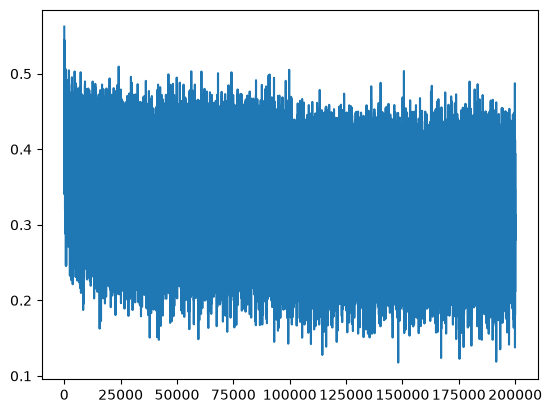

In [34]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] 

    # forward pass
    emb = C[Xb]
    embcat = emb.view(batch_size, -1)
    hpreact = embcat @ W1 # + b1
    # ------------ changed
    hpreact = bngain * ((hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True)) + bnbias
    # ------------ changed
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats:
    if i == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    # break

# plot the loss over time
plt.plot(lossi)

In [35]:
# calculate the mean and std overall for the loss function of the whole dataset and deployment
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1
    bnmean = hpreact.mean(0, keepdims=True)
    bnstd = hpreact.std(0, keepdims=True)
bnmean, bnstd

(tensor([[-1.8117e+00, -8.6841e-01, -1.6617e+00,  7.3871e-01,  7.5298e-01,
          -1.6706e-01,  1.9126e+00, -1.8389e+00,  3.2332e-01,  1.2963e+00,
          -1.1362e+00, -2.5063e+00, -4.6804e-01, -9.3644e-01, -9.3362e-01,
          -2.7964e-01,  9.0597e-01, -3.3787e+00,  3.1607e-01,  1.9636e+00,
           5.4346e-01, -2.3205e-01, -1.3456e+00,  7.2838e-01,  1.7117e+00,
          -7.6130e-02,  8.2479e-01,  1.0355e-01,  3.3989e-02,  1.9373e+00,
          -2.7788e-01, -7.1123e-01,  9.1477e-02,  7.5977e-01, -1.1535e+00,
          -1.1434e+00, -2.2573e+00,  1.8141e+00, -4.7690e-01,  2.5085e-01,
          -6.1606e-01, -4.2926e-01, -9.4145e-01, -7.6126e-02,  6.3681e-01,
           7.1094e-01,  1.7302e+00, -7.7646e-02,  1.5022e+00,  1.6929e+00,
           2.2530e+00,  2.5270e-02,  2.4172e+00, -2.2365e-01,  2.5607e-01,
          -1.2660e+00, -7.7480e-01,  1.9307e-01,  1.3357e+00, -1.7417e+00,
          -1.1605e+00,  1.2114e+00,  4.5937e-01,  6.2557e-01,  4.8724e-01,
           9.2474e-01, -1

In [37]:
@torch.no_grad() # this decorator disables gradient tracking
# decorator only affects the function defined directly below it
def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1
    # ------------- changed
    hpreact = bngain * ((hpreact - bnmean) / bnstd) + bnbias
    # ------------- changed
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0687668323516846
val 2.108649969100952


### Running mean/std

In [40]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.zeros(vocab_size)


bngain = torch.ones(1, n_hidden) 
bnbias = torch.zeros(1, n_hidden) 
# ------------- changed
bnmean_running = torch.zeros(1, n_hidden) 
# we can set it to one since the hpreact distribution should be Gaussian upon initialization
bnstd_running = torch.ones(1, n_hidden)
# same thing above
# ------------- changed

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

12097


      1/ 200000: 3.6502
  10000/ 200000: 2.5414
  20000/ 200000: 2.0222
  30000/ 200000: 2.1156
  40000/ 200000: 2.1786
  50000/ 200000: 2.3081
  60000/ 200000: 2.4909
  70000/ 200000: 2.3764
  80000/ 200000: 1.6840
  90000/ 200000: 1.8305
 100000/ 200000: 2.0461
 110000/ 200000: 1.7812
 120000/ 200000: 2.0385
 130000/ 200000: 2.0709
 140000/ 200000: 2.3617
 150000/ 200000: 2.2657
 160000/ 200000: 2.0671
 170000/ 200000: 2.4209
 180000/ 200000: 1.9358
 190000/ 200000: 1.9251
 200000/ 200000: 2.0552


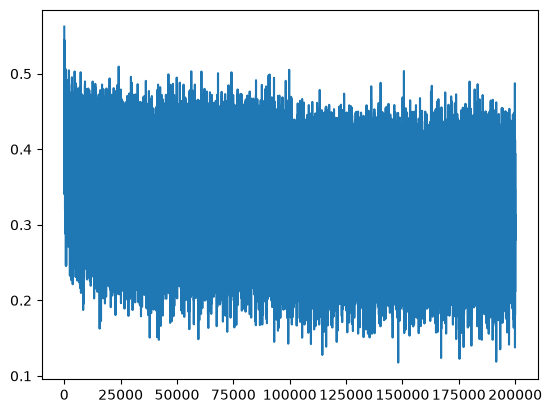

In [41]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] 

    # forward pass
    emb = C[Xb]
    embcat = emb.view(batch_size, -1)
    hpreact = embcat @ W1 # + b1
    # ------------ changed 
    bnmeani = hpreact.mean(0, keepdims=True)
    bnstdi = hpreact.std(0, keepdims=True)
    # store them in another variable so that the running mean/std can be changed easily
    hpreact = bngain * ((hpreact - bnmeani)/bnstdi) + bnbias
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # the value 0.999 and 0.001 are decided so that bnmean/bnstd are not changing too fast or slow
    # you can move it around, as long as the two weights add up to one
    # ------------ changed
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats:
    if i == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    # break

# plot the loss over time
plt.plot(lossi)

In [42]:
# you can compare it to the deterministic values in the other way
bnmean_running, bnstd_running

(tensor([[-1.8049e+00, -8.6195e-01, -1.6614e+00,  7.4358e-01,  7.5887e-01,
          -1.8695e-01,  1.9005e+00, -1.8471e+00,  3.2025e-01,  1.2907e+00,
          -1.1403e+00, -2.5015e+00, -4.6808e-01, -9.3848e-01, -9.3320e-01,
          -2.7409e-01,  9.0445e-01, -3.3833e+00,  2.9348e-01,  1.9436e+00,
           5.4365e-01, -2.1723e-01, -1.3334e+00,  7.3998e-01,  1.7142e+00,
          -8.1490e-02,  8.2521e-01,  1.0189e-01,  3.6475e-02,  1.9274e+00,
          -2.9925e-01, -7.0469e-01,  9.4370e-02,  7.5637e-01, -1.1487e+00,
          -1.1423e+00, -2.2558e+00,  1.7944e+00, -4.6562e-01,  2.5621e-01,
          -6.2641e-01, -4.5296e-01, -9.4023e-01, -8.3477e-02,  6.5304e-01,
           7.3358e-01,  1.7414e+00, -7.6157e-02,  1.5005e+00,  1.6979e+00,
           2.2561e+00,  1.1871e-02,  2.4159e+00, -2.1709e-01,  2.5388e-01,
          -1.2607e+00, -7.7490e-01,  1.9414e-01,  1.3471e+00, -1.7448e+00,
          -1.1703e+00,  1.2055e+00,  4.5684e-01,  6.1730e-01,  5.0042e-01,
           9.2345e-01, -1

In [43]:
@torch.no_grad() # this decorator disables gradient tracking
# decorator only affects the function defined directly below it
def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1
    # ------------- changed
    hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbias
    # ------------- changed
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.068492889404297
val 2.108814239501953


# Corresponding objects in pytorch

### Linear layer

![linear layer](linear.png)

A slight distinction between this function in pytorch and our implementation above is that this function uses uniform distribution to initialize the weight and bias instead of uniform distribution. 

### Batchnormalization

![batchnormalization layer 1](normalization1.png)

![batchnormalization layer 2](normalization2.png)

Side note: the setting of momentum is dependent on the batch size. For our case in which each minibatch has only 32 samples, it needs to be much lower than the 0.1 default value, like 0.001 as set in the loop above. 